# Lab-3 Descriptive Statistics and Visualization

1. Measures of Central Tendency (mean, median, mode)
2. Measures of Dispersion (variance, standard deviation, IQR)
3. Measures of Distribution Shape (skewness, kurtosis)
4. Data Visualizations (histograms, box plots, scatter plots)
5. Comparative Summary and Practical Guidance

The goal is not just to *compute* these statistics, but to build intuition for **when each one is
useful, what it tells you, and what it can hide.** Every concept is tied back to a concrete column
in our dataset so the numbers always mean something.

> **Audience:** this notebook assumes only basic familiarity with Python/pandas and no prior
> statistics background.

**Name:** Francis Reuben R  
**USN:** 1RUA25CSE0168  
**Section:** G


In [1]:
%matplotlib inline
#     Core libraries used throughout the notebook    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Reproducibility: fixing the seed means everyone who runs this notebook gets identical numbers
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Plot styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

print("Libraries loaded. Random seed set to", RANDOM_SEED)

Libraries loaded. Random seed set to 42


In [2]:
# The four numeric features we will analyze throughout the notebook
FEATURES = ["exam_score", "monthly_allowance_inr", "quiz_score", "weekly_study_hours"]
df=pd.read_csv("student_survey_synthetic.csv")


**A quick sanity check before we analyze anything:** it's good practice to look at `.describe()`
and the data types before diving into specific statistics — this catches obvious data issues early
(wrong types, impossible values, missing data) and gives a first rough impression of scale and
spread for each column.

In [3]:
df.describe()

,exam_score,monthly_allowance_inr,quiz_score,weekly_study_hours
count,160.000,160.000,160.000,160.000
mean,71.931,4414.375,14.035,10.667
std,7.658,1909.942,2.764,7.105
min,53.120,1600.000,3.570,0.950
25%,66.330,3010.000,12.685,4.647
50%,72.150,4015.000,14.625,6.315
75%,77.220,5222.500,16.055,18.172
max,98.980,13790.000,18.670,24.140


In [4]:
df.describe(include=[object, "string"])

,student_id,preferred_language
count,160,160
unique,160,4
top,S001,Python
freq,1,82


## 2. Measures of Central Tendency

Central tendency measures try to answer one question: **"what's a typical value in this data?"**
There are three common answers, and they are not interchangeable:

- **Mean** (average): sum of all values divided by how many there are. It uses every data point,
  which makes it efficient but also sensitive — one extreme value can pull it a long way.
- **Median**: the middle value when the data is sorted (or the average of the two middle values).
  It only cares about *position*, not magnitude, so extreme values barely move it.
- **Mode**: the most frequently occurring value. It's the only one of the three that makes sense
  for **categorical or discrete** data (you can't "average" favorite programming languages, but
  you can ask which one comes up most often).

**Rule of thumb:** use the mean when the data is roughly symmetric and outlier-free; switch to the
median when the data is skewed or contains outliers, because the median describes the "typical"
student far more honestly in those cases; use the mode when you care about the most common
category or the most frequent discrete value, not an averaged one.

In [5]:
df = pd.read_csv("student_survey_synthetic.csv")
print(df.columns)
column = "exam_score"   
mean_value = df[column].mean()
print("Mean:", mean_value)

Index(['student_id', 'exam_score', 'monthly_allowance_inr', 'quiz_score',
       'weekly_study_hours', 'preferred_language'],
      dtype='str')
Mean: 71.9306875


In [6]:
median_value = df[column].median()
print("Median:", median_value)

Median: 72.15


**Why is "mode" barely useful above?** Continuous measurements (like `exam_score`, rounded to two
decimal places) almost never repeat exactly, so the "most common value" is often just an
arbitrary tie-breaker rather than a meaningful typical value. Mode shines instead on **categorical
or discrete** data, where repeated exact values are the norm:

In [7]:
mode_values = df[column].mode()
print("Mode:", mode_values.tolist())

Mode: [66.33]


### When mean and median disagree: the outlier effect

The clearest way to see the mean's sensitivity to outliers is to watch what happens when we add a
single extreme value. Take `monthly_allowance_inr`, our right-skewed feature: suppose one student
receives a one-time scholarship payout of ₹150,000 that month. We'll add this one hypothetical
value to a **copy** of the data and compare.

Original mean:    4414.375
Original median:  4015.0
New mean:         5318.633540372671
New median:       4030.0


/var/folders/ms/xxfv0sjx2hlg_whs4jpbm8hm0000gn/T/ipykernel_61710/21878852.py:40: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/maverick/.venvs/dslab/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


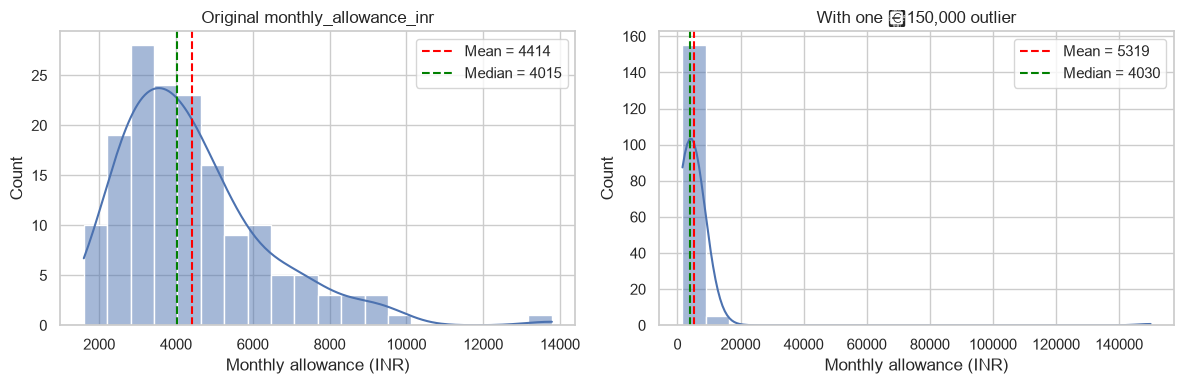

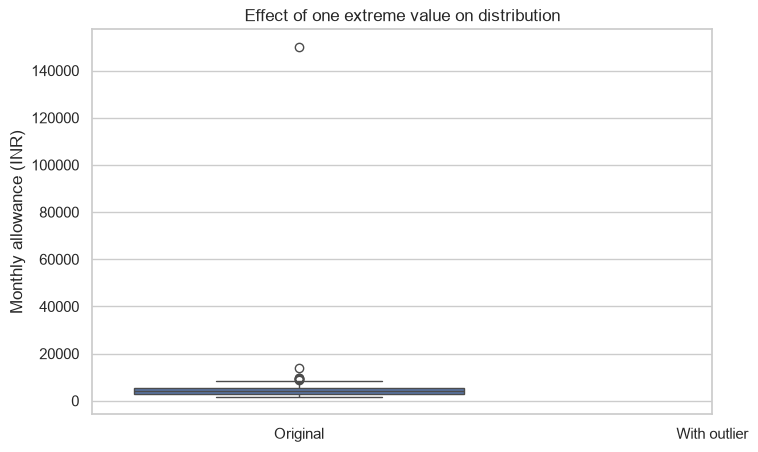

In [8]:
sns.set(style="whitegrid")

# Work on a copy and add one extreme outlier
df_out = df.copy()
outlier_value = 150_000
df_out.loc[len(df_out)] = df_out.iloc[-1].copy()  # duplicate last row
df_out.loc[df_out.index[-1], "monthly_allowance_inr"] = outlier_value

# Compute stats
original_mean = df["monthly_allowance_inr"].mean()
original_median = df["monthly_allowance_inr"].median()

new_mean = df_out["monthly_allowance_inr"].mean()
new_median = df_out["monthly_allowance_inr"].median()

print("Original mean:   ", original_mean)
print("Original median: ", original_median)
print("New mean:        ", new_mean)
print("New median:      ", new_median)

#                         -
# Plot 1: Histograms side by side
#                         -
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["monthly_allowance_inr"], kde=True, ax=axes[0], bins=20)
axes[0].set_title("Original monthly_allowance_inr")
axes[0].set_xlabel("Monthly allowance (INR)")
axes[0].axvline(original_mean, color="red", linestyle="--", label=f"Mean = {original_mean:.0f}")
axes[0].axvline(original_median, color="green", linestyle="--", label=f"Median = {original_median:.0f}")
axes[0].legend()

sns.histplot(df_out["monthly_allowance_inr"], kde=True, ax=axes[1], bins=20)
axes[1].set_title("With one ₹150,000 outlier")
axes[1].set_xlabel("Monthly allowance (INR)")
axes[1].axvline(new_mean, color="red", linestyle="--", label=f"Mean = {new_mean:.0f}")
axes[1].axvline(new_median, color="green", linestyle="--", label=f"Median = {new_median:.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()

#                         -
# Plot 2: Boxplots comparison
#                         -
plt.figure(figsize=(8, 5))
data_to_plot = [df["monthly_allowance_inr"], df_out["monthly_allowance_inr"]]
labels = ["Original", "With outlier"]

sns.boxplot(data=data_to_plot)
plt.xticks(ticks=[0, 1], labels=labels)
plt.ylabel("Monthly allowance (INR)")
plt.title("Effect of one extreme value on distribution")
plt.show()

**Interpretation:** a single unusual value dragged the mean sharply upward, but the median barely
moved, because the median only depends on which value sits in the middle position — and adding one
extra point far out in the tail doesn't change *what's in the middle*. This is exactly why the
median is described as **robust** to outliers, and why right-skewed data (like income, prices, or
allowances) is usually summarized with a median rather than a mean in real reporting.

Note that `monthly_allowance_inr` and `quiz_score` already show mean and median pulling apart even
*without* an artificial outlier — that's the natural fingerprint of skewness, which we'll quantify
precisely in Section 4.

## 3. Measures of Dispersion

Central tendency tells us where the "middle" of the data is, but says nothing about how **spread
out** the values are around that middle. Two features can have the same mean and look completely
different. Three common measures of spread:

- **Variance**: the average of the squared deviations from the mean. Squaring guarantees a
  non-negative measure and gives larger deviations disproportionately more weight, but it also
  changes the *units* (e.g., "score points squared"), which makes variance hard to interpret
  directly.
- **Standard deviation**: simply the square root of the variance. This brings the units back to
  the original scale (e.g., "score points"), which is why standard deviation — not variance — is
  the number people usually quote and interpret ("scores typically fall within about 8 points of
  the mean").
- **Interquartile range (IQR)**: the range covered by the middle 50% of the data (`Q3 - Q1`). Like
  the median, it ignores the extreme tails entirely, so it is **robust to outliers** in the same
  way the median is — a useful pairing when your central tendency measure is also the median.

**When to prefer which:** use standard deviation alongside the mean for roughly symmetric,
outlier-free data (it's the natural companion in that setting); use IQR alongside the median when
the data is skewed or has outliers, since both are computed only from ranked positions and stay
stable even if the tails stretch further.

### Manual calculation, step by step

Before relying on built-in functions, let's calculate the variance and standard deviation of
`exam_score` by hand, following the definition directly:

$$
\text{variance} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1}
\qquad\qquad
\text{standard deviation} = \sqrt{\text{variance}}
$$

(We divide by `n - 1`, not `n` — this is the *sample* variance formula, which corrects a slight
downward bias that occurs when the mean itself is estimated from the same sample. `pandas` and
`numpy`'s `ddof=1` option use this convention by default in `.var()`/`.std()`.)

In [9]:
#     Manual, step-by-step variance & standard deviation for exam_score    
x = df["exam_score"].values
n_obs = len(x)

# Step 1: Compute the sample mean
mean_x = sum(x) / n_obs

# Step 2: Compute deviations from the mean (x_i - mean)
deviations = [xi - mean_x for xi in x]

# Step 3: Square each deviation to remove negative signs and penalize larger spread
squared_deviations = [d**2 for d in deviations]

# Step 4: Sum squared deviations and divide by (n - 1) for Bessel's sample correction
manual_var = sum(squared_deviations) / (n_obs - 1)

# Step 5: Take the square root to return to original units
manual_std = manual_var ** 0.5


print(f"Sample Size (n):      {n_obs}")
print(f"Sample Mean:          {mean_x:.4f}")
print(f"Manual Variance:      {manual_var:.4f}")
print(f"Manual Std Dev:       {manual_std:.4f}")

Sample Size (n):      160
Sample Mean:          71.9307
Manual Variance:      58.6445
Manual Std Dev:       7.6580


In [10]:
# Pandas uses ddof=1 (sample variance/std) by default
pd_var = df["exam_score"].var()
pd_std = df["exam_score"].std()

print("Pandas built-in cross-check")
print(f"Pandas Variance: {pd_var:.4f} (Diff: {abs(manual_var - pd_var):.1e})")
print(f"Pandas Std Dev:  {pd_std:.4f} (Diff: {abs(manual_std - pd_std):.1e})")


Pandas built-in cross-check
Pandas Variance: 58.6445 (Diff: 2.8e-14)
Pandas Std Dev:  7.6580 (Diff: 1.8e-15)


## IQR — Interquartile Range

IQR measures the spread of the middle 50% of the data.

$$ \boxed{IQR=Q_3-Q_1} $$

where:

Q1= 25th percentile
Q2= 50th percentile (median)
Q3 = 75th percentile

In [11]:
x = df["monthly_allowance_inr"].values
x_sorted = np.sort(x)
q1 = np.percentile(x_sorted, 25)
q3 = np.percentile(x_sorted, 75)
manual_iqr = q3 - q1
print(x_sorted)
print(f"\nQ1 (25th percentile): {q1:.4f}")
print(f"Q3 (75th percentile): {q3:.4f}")
print(f"Manual IQR (Q3 - Q1): {manual_iqr:.4f}")

#     Outlier detection on monthly_allowance_inr via IQR    
col = "monthly_allowance_inr"

# 1. Calculate Q1, Q3, and IQR
q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3 - q1

# 2. Define upper and lower bounds (Tukey's fences)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1 (25%):        ₹{q1:,.2f}")
print(f"Q3 (75%):        ₹{q3:,.2f}")
print(f"IQR:             ₹{iqr:,.2f}")
print(f"Lower Bound:     ₹{lower_bound:,.2f}")
print(f"Upper Bound:     ₹{upper_bound:,.2f}")

# 3. Filter values strictly greater than upper bound (high outliers)
high_outliers = df[df[col] > upper_bound]

# 4. Filter values strictly lesser than lower bound (low outliers)
low_outliers = df[df[col] < lower_bound]

print(f"\n    Values GREATER than Upper Bound ({len(high_outliers)} found)    ")
display(high_outliers[["student_id", col]])

print(f"\n    Values LESS than Lower Bound ({len(low_outliers)} found)    ")
display(low_outliers[["student_id", col]])


df_cleaned = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)].copy()

df_cleaned.reset_index(drop=True, inplace=True)

print(f"Original row count: {len(df)}")
print(f"Cleaned row count:  {len(df_cleaned)}")
print(f"Rows removed:       {len(df) - len(df_cleaned)}")


[ 1600.  1720.  1760.  1780.  1990.  2030.  2040.  2130.  2180.  2190.
  2250.  2290.  2320.  2370.  2390.  2480.  2490.  2510.  2570.  2630.
  2630.  2660.  2690.  2690.  2710.  2740.  2760.  2810.  2810.  2880.
  2890.  2890.  2900.  2900.  2910.  2930.  2950.  2960.  2970.  2980.
  3020.  3040.  3070.  3170.  3170.  3190.  3200.  3210.  3220.  3250.
  3250.  3260.  3280.  3290.  3330.  3340.  3360.  3430.  3540.  3590.
  3600.  3610.  3640.  3640.  3680.  3690.  3770.  3790.  3800.  3840.
  3850.  3850.  3860.  3880.  3920.  3940.  3970.  3990.  3990.  4000.
  4030.  4040.  4060.  4080.  4100.  4130.  4140.  4150.  4180.  4180.
  4210.  4220.  4270.  4330.  4380.  4400.  4420.  4440.  4440.  4560.
  4560.  4580.  4600.  4610.  4660.  4690.  4730.  4750.  4900.  4910.
  4920.  4940.  4950.  5070.  5110.  5140.  5160.  5160.  5170.  5210.
  5260.  5290.  5300.  5350.  5360.  5450.  5520.  5670.  5700.  5890.
  5900.  5910.  5940.  5940.  6140.  6300.  6390.  6450.  6450.  6600.
  6710

,student_id,monthly_allowance_inr
3,S004,9290.0
54,S055,9520.0
58,S059,9660.0
100,S101,9180.0
140,S141,8830.0
158,S159,13790.0



    Values LESS than Lower Bound (0 found)    


,student_id,monthly_allowance_inr


Original row count: 160
Cleaned row count:  154
Rows removed:       6


In [12]:
# Dispersion table for all four numeric features
disp = pd.DataFrame({
    "variance": df[FEATURES].var(),
    "std": df[FEATURES].std(),
    "Q1": df[FEATURES].quantile(0.25),
    "Q3": df[FEATURES].quantile(0.75),
})
disp["IQR"] = disp["Q3"] - disp["Q1"]
display(disp)


,variance,std,Q1,Q3,IQR
exam_score,5.864e+01,7.658,66.330,77.220,10.890
monthly_allowance_inr,3.648e+06,1909.942,3010.000,5222.500,2212.500
quiz_score,7.641e+00,2.764,12.685,16.055,3.370
weekly_study_hours,5.048e+01,7.105,4.647,18.172,13.525


**Reading this table:** notice `monthly_allowance_inr` has a huge variance/std simply because it is
measured in rupees on a much larger numeric scale than, say, `quiz_score` out of 20 — variance and
standard deviation are **not comparable across features with different units or scales** without
standardizing first (we'll do this in Section 5 for the box plot comparison). IQR has the same
scale issue, but within a single skewed feature it remains a more trustworthy "typical spread"
than variance/std, since it isn't inflated by the long tail the way squared deviations are.

## 4. Measures of Distribution Shape

Central tendency and dispersion tell us "where" and "how spread out," but not "what shape." Two
features can share the same mean and standard deviation while looking completely different when
plotted. Skewness and kurtosis quantify shape numerically.

- **Skewness** measures asymmetry — which side has the longer tail.
  - Skewness **≈ 0**: roughly symmetric (like a normal distribution).
  - Skewness **> 0** (right/positive skew): a long tail stretches to the **right**; typically
    `mean > median` because a few large values pull the mean upward.
  - Skewness **< 0** (left/negative skew): a long tail stretches to the **left**; typically
    `mean < median` because a few small values pull the mean downward.

- **Kurtosis** (we use *excess* kurtosis, i.e. relative to the normal distribution's value of 0)
  measures tail heaviness and peak sharpness.
  - Excess kurtosis **≈ 0** (mesokurtic): tails behave like a normal distribution.
  - Excess kurtosis **> 0** (leptokurtic): heavier tails and/or a sharper peak than normal — more
    extreme outliers than you'd expect from a normal curve.
  - Excess kurtosis **< 0** (platykurtic): lighter tails and a flatter, more spread-out peak — data
    is more "spread across the middle" than a normal curve, which is exactly what a **bimodal**
    distribution tends to look like (probability mass pulled away from the center into two humps).

Together, skewness and kurtosis are a quick numerical check for **departures from normality** —
useful because many classical statistical methods (t-tests, linear regression, etc.) assume
approximately normal data.

**Tying this back to how we designed the data:**

- `exam_score` was built to be approximately normal, and indeed its skewness and excess kurtosis
  both sit close to 0.
- `monthly_allowance_inr` was built right-skewed (lognormal), which shows up as clearly positive
  skewness — consistent with the mean sitting above the median we saw in Section 2.
- `quiz_score` was built left-skewed (a ceiling effect where most students score high), and its
  skewness comes out negative, matching `mean < median` from Section 2.
- `weekly_study_hours` was built as a **mixture of two groups** (bimodal). Its skewness is modest,
  but notice the **negative excess kurtosis** — this is the classic numeric signature of a
  flatter-than-normal, two-humped shape. This is also a great cautionary example: **skewness and
  kurtosis alone cannot conclusively prove a distribution is bimodal** — a low/negative kurtosis is
  a hint, but only a histogram (Section 5) actually *shows* the two humps directly. Summary
  statistics can point you in the right direction, but they can also hide structure that only a
  picture reveals.

## Distribution of exam_score


In [13]:
# Define numeric features
FEATURES = ["exam_score", "monthly_allowance_inr", "quiz_score", "weekly_study_hours"]

# Compute Skewness and Excess Kurtosis (Fisher's definition: normal = 0)
shape_summary = pd.DataFrame({
    "Mean": df[FEATURES].mean(),
    "Median": df[FEATURES].median(),
    "Skewness": df[FEATURES].skew(),
    "Excess Kurtosis": df[FEATURES].kurtosis()  # pandas kurtosis is excess kurtosis by default
})

# Classify shape based on thresholds
def classify_skew(val):
    if val > 0.5: return "Right (Positive) Skew"
    elif val < -0.5: return "Left (Negative) Skew"
    else: return "Symmetric"

def classify_kurtosis(val):
    if val > 0.5: return "Leptokurtic (Heavy tail)"
    elif val < -0.5: return "Platykurtic (Flat/Bimodal)"
    else: return "Mesokurtic (Normal-like)"

shape_summary["Skew Type"] = shape_summary["Skewness"].apply(classify_skew)
shape_summary["Kurtosis Type"] = shape_summary["Excess Kurtosis"].apply(classify_kurtosis)

display(shape_summary.round(3))

,Mean,Median,Skewness,Excess Kurtosis,Skew Type,Kurtosis Type
exam_score,71.931,72.150,0.132,0.211,Symmetric,Mesokurtic (Normal-like)
monthly_allowance_inr,4414.375,4015.000,1.445,3.303,Right (Positive) Skew,Leptokurtic (Heavy tail)
quiz_score,14.035,14.625,-1.124,1.407,Left (Negative) Skew,Leptokurtic (Heavy tail)
weekly_study_hours,10.667,6.315,0.435,-1.532,Symmetric,Platykurtic (Flat/Bimodal)


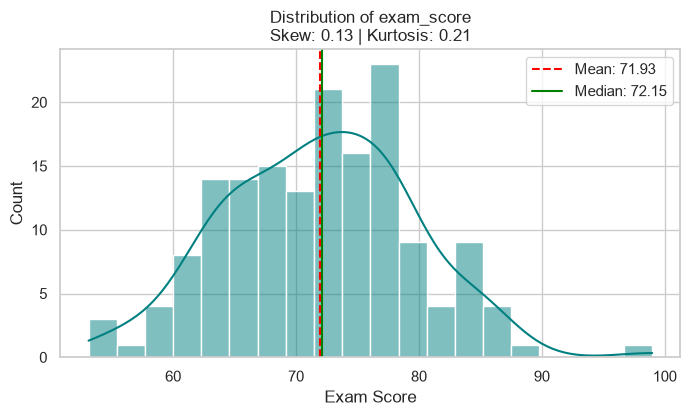

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(df["exam_score"], kde=True, color="teal", bins=20)
plt.axvline(df["exam_score"].mean(), color="red", linestyle="--", label=f"Mean: {df['exam_score'].mean():.2f}")
plt.axvline(df["exam_score"].median(), color="green", linestyle="-", label=f"Median: {df['exam_score'].median():.2f}")
plt.title(f"Distribution of exam_score\nSkew: {df['exam_score'].skew():.2f} | Kurtosis: {df['exam_score'].kurtosis():.2f}")
plt.xlabel("Exam Score")
plt.legend()
plt.show()

## Distribution of monthly_allowance_inr

/Users/maverick/.venvs/dslab/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


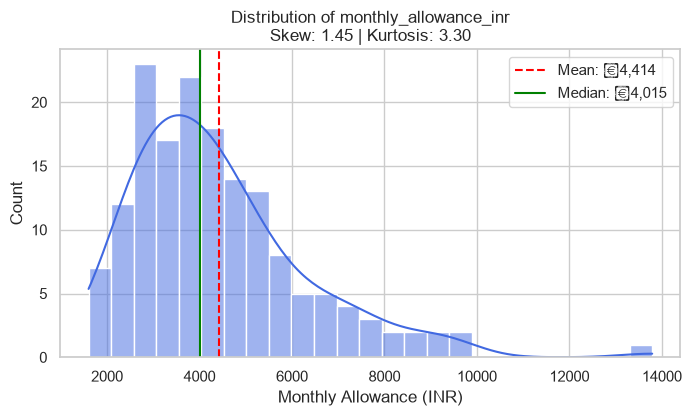

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(df["monthly_allowance_inr"], kde=True, color="royalblue", bins=25)
plt.axvline(df["monthly_allowance_inr"].mean(), color="red", linestyle="--", label=f"Mean: ₹{df['monthly_allowance_inr'].mean():,.0f}")
plt.axvline(df["monthly_allowance_inr"].median(), color="green", linestyle="-", label=f"Median: ₹{df['monthly_allowance_inr'].median():,.0f}")
plt.title(f"Distribution of monthly_allowance_inr\nSkew: {df['monthly_allowance_inr'].skew():.2f} | Kurtosis: {df['monthly_allowance_inr'].kurtosis():.2f}")
plt.xlabel("Monthly Allowance (INR)")
plt.legend()
plt.show()

## Distribution of quiz_score

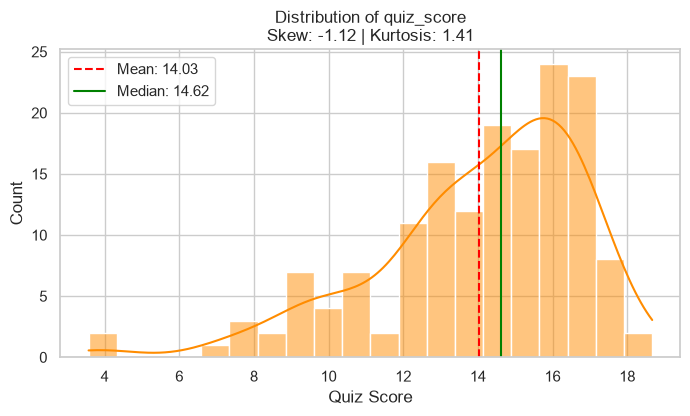

In [16]:
plt.figure(figsize=(8, 4))
sns.histplot(df["quiz_score"], kde=True, color="darkorange", bins=20)
plt.axvline(df["quiz_score"].mean(), color="red", linestyle="--", label=f"Mean: {df['quiz_score'].mean():.2f}")
plt.axvline(df["quiz_score"].median(), color="green", linestyle="-", label=f"Median: {df['quiz_score'].median():.2f}")
plt.title(f"Distribution of quiz_score\nSkew: {df['quiz_score'].skew():.2f} | Kurtosis: {df['quiz_score'].kurtosis():.2f}")
plt.xlabel("Quiz Score")
plt.legend()
plt.show()

## Distribution of weekly_study_hours

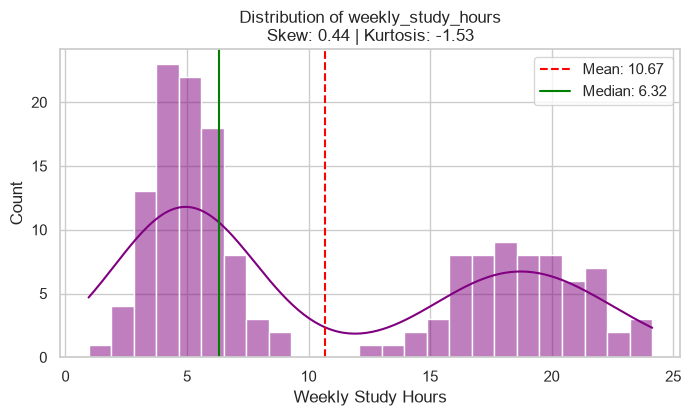

In [17]:
plt.figure(figsize=(8, 4))
sns.histplot(df["weekly_study_hours"], kde=True, color="purple", bins=25)
plt.axvline(df["weekly_study_hours"].mean(), color="red", linestyle="--", label=f"Mean: {df['weekly_study_hours'].mean():.2f}")
plt.axvline(df["weekly_study_hours"].median(), color="green", linestyle="-", label=f"Median: {df['weekly_study_hours'].median():.2f}")
plt.title(f"Distribution of weekly_study_hours\nSkew: {df['weekly_study_hours'].skew():.2f} | Kurtosis: {df['weekly_study_hours'].kurtosis():.2f}")
plt.xlabel("Weekly Study Hours")
plt.legend()
plt.show()

## 5. Data Visualizations

Numbers alone can mislead — this is sometimes called "Anscombe's quartet problem," where wildly
different-looking datasets share identical means, variances, and correlations. Visualizations let
us confirm (or challenge) what the summary statistics suggested, and they reveal structure — like
the bimodal split in `weekly_study_hours` — that a single number cannot.

**Insight this gives that raw numbers can't:** you can *see* exactly how mean and median relate to
each tail — for `monthly_allowance_inr`, the mean is visibly pulled right of the median by the long
tail of high earners; for `quiz_score`, it's pulled left. For `weekly_study_hours`, the mean and
median both land in the empty "valley" between the two humps — a value that hardly any actual
student has. This is the single clearest illustration in the whole notebook of why a central
tendency number can be actively misleading without a picture to check it against.

### 5.1 Box plots

A box plot summarizes five numbers at once: the minimum (within 1.5×IQR of Q1), Q1 (25th
percentile), the median (Q2, 50th percentile), Q3 (75th percentile), and the maximum (within
1.5×IQR of Q3) — with any points beyond that range flagged as individual outlier dots. It's a
compact way to compare spread and skewness *across several features at once*, which a table of
numbers makes you compare column by column.

Because our four features live on very different scales (₹ vs. hours vs. a 0-100 score vs. a 0-20
score), we standardize each feature to a common z-score scale (mean 0, standard deviation 1) purely
for this side-by-side comparison — standardizing preserves each feature's *shape* while making the
spreads visually comparable.

**Insight this gives that raw numbers can't:** side-by-side boxes make skewness visible as an
*asymmetric* box — notice how `monthly_allowance_inr`'s box and whisker stretch much further above
the median than below it (right-skew), the mirror image for `quiz_score`, and how
`monthly_allowance_inr` shows individual outlier dots above the top whisker, flagging the same
"a few students earn a lot more" pattern we quantified with skewness in Section 4 — but now you can
see exactly how many outliers there are and how extreme each one is, which a single skewness number
cannot show.

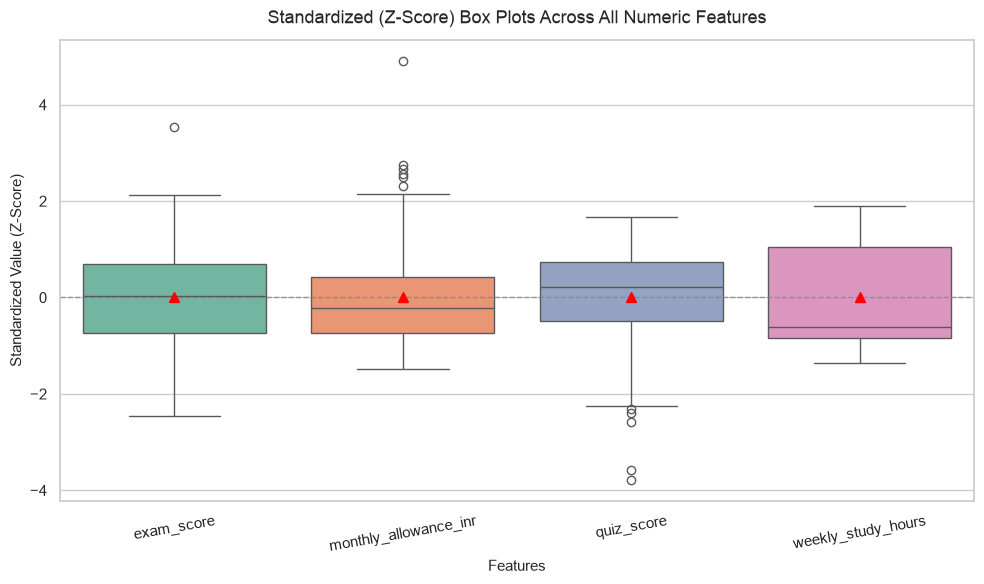

In [18]:
# Numeric features list
FEATURES = ["exam_score", "monthly_allowance_inr", "quiz_score", "weekly_study_hours"]

# 1. Standardize (Z-score normalization: z = (x - mean) / std)
# Using sample std (ddof=1)
df_standardized = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()

# 2. Plot side-by-side boxplots
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_standardized,
    palette="Set2",
    showmeans=True,  # Displays the mean as a marker (green triangle)
    meanprops={"marker": "^", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 7}
)

# Reference line at mean = 0
plt.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="Mean (0)")

plt.title("Standardized (Z-Score) Box Plots Across All Numeric Features", fontsize=13, pad=12)
plt.ylabel("Standardized Value (Z-Score)", fontsize=11)
plt.xlabel("Features", fontsize=11)
plt.xticks(ticks=range(len(FEATURES)), labels=FEATURES, rotation=10)
plt.tight_layout()
plt.show()


### 5.2 Scatter plots

Scatter plots reveal **relationships between two features** — something no single-feature
statistic (mean, std, skewness, etc.) can show at all, no matter how many of them you compute. We
show one pair with a clear relationship and one pair with essentially none, so you can compare what
"a real pattern" looks like against "no pattern" side by side.

## quiz_score vs exam_score

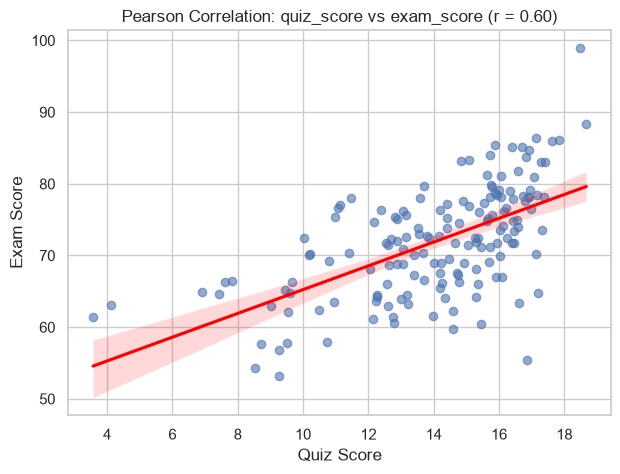

In [19]:
r1 = df["quiz_score"].corr(df["exam_score"])

plt.figure(figsize=(7, 5))
sns.regplot(
    data=df,
    x="quiz_score",
    y="exam_score",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
plt.title(f"Pearson Correlation: quiz_score vs exam_score (r = {r1:.2f})")
plt.xlabel("Quiz Score")
plt.ylabel("Exam Score")
plt.show()

## quiz_score vs monthly_allowance_inr

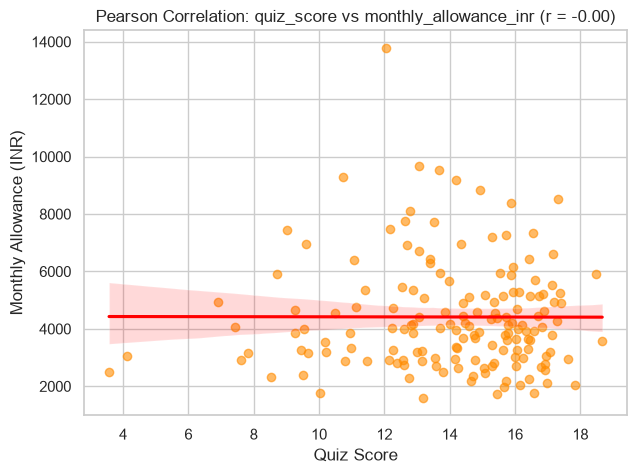

In [20]:
r2 = df["quiz_score"].corr(df["monthly_allowance_inr"])

plt.figure(figsize=(7, 5))
sns.regplot(
    data=df,
    x="quiz_score",
    y="monthly_allowance_inr",
    color="darkorange",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
plt.title(f"Pearson Correlation: quiz_score vs monthly_allowance_inr (r = {r2:.2f})")
plt.xlabel("Quiz Score")
plt.ylabel("Monthly Allowance (INR)")
plt.show()

### Pearson Correlation Coefficient

The **Pearson correlation coefficient** measures the strength and direction of the linear relationship between two numerical variables, $X$ and $Y$.

The formula is:

$$
\boxed{
r =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}
}
}
$$

where:

- $r$ = Pearson correlation coefficient
- $x_i$ = individual observation of variable $X$
- $y_i$ = individual observation of variable $Y$
- $\bar{x}$ = mean of variable $X$
- $\bar{y}$ = mean of variable $Y$
- $n$ = number of observations

The Pearson correlation coefficient always lies between:

$$
\boxed{-1 \leq r \leq +1}
$$

### Interpretation of Correlation Values

| Correlation ($r$) | Interpretation |
|   :|   |
| $+1.00$ | Perfect positive correlation |
| $+0.70$ to $+0.99$ | Strong positive correlation |
| $+0.30$ to $+0.69$ | Moderate positive correlation |
| $-0.29$ to $+0.29$ | Weak or little linear correlation |
| $-0.30$ to $-0.69$ | Moderate negative correlation |
| $-0.70$ to $-0.99$ | Strong negative correlation |
| $-1.00$ | Perfect negative correlation |

### Direction of Correlation

**Positive correlation:**

$$
X\uparrow \Rightarrow Y\uparrow
$$

As $X$ increases, $Y$ tends to increase.

**Negative correlation:**

$$
X\uparrow \Rightarrow Y\downarrow
$$

As $X$ increases, $Y$ tends to decrease.

**No linear correlation:**

$$
r\approx0
$$

There is little or no **linear** relationship between $X$ and $Y$.

### Example

Suppose:

$$
r(\text{quiz score},\text{exam score})=0.82
$$

This indicates a **strong positive linear relationship** between quiz score and exam score. Students with higher quiz scores tend to have higher exam scores.

### Important Points

1. **Correlation does not imply causation.**  
   A strong correlation does not prove that one variable causes changes in another.

2. **Pearson correlation measures linear relationships.**  
   A correlation close to zero does not necessarily mean that there is no relationship. The variables may have a strong nonlinear relationship.

3. **Outliers can affect Pearson correlation.**  
   Therefore, a scatter plot should be examined before interpreting the correlation coefficient.

4. **Only appropriate numerical variables should be included.**  
   Identifier columns such as `student_id` and categorical variables such as `preferred_language` should not be directly included in a Pearson correlation matrix.

### Key Takeaway

> **A correlation heatmap provides a quick visual summary of the direction and strength of linear relationships among numerical variables. Pearson correlation quantifies this relationship on a scale from $-1$ to $+1$.**

In [21]:
# Manual Pearson r for quiz_score vs exam_score (same formula as the markdown cell)
x = df["quiz_score"]
y = df["exam_score"]
num = ((x - x.mean()) * (y - y.mean())).sum()
den = (((x - x.mean()) ** 2).sum() * ((y - y.mean()) ** 2).sum()) ** 0.5
r_manual = num / den
print(f"Manual Pearson r (quiz_score, exam_score): {r_manual:.4f}")
print(f"pandas .corr() check: {x.corr(y):.4f}")


Manual Pearson r (quiz_score, exam_score): 0.5988
pandas .corr() check: 0.5988


## Pearson Correlation  quiz_score vs exam_score

In [22]:
# --- Pearson Correlation: quiz_score vs exam_score ---
r_quiz_exam = df["quiz_score"].corr(df["exam_score"])
print(f"Pearson correlation (quiz_score, exam_score): {r_quiz_exam:.4f}")

Pearson correlation (quiz_score, exam_score): 0.5988


## Pearson Correlation  quiz_score vs monthly_allowance_inr

In [23]:
# Pearson correlation: quiz_score vs monthly_allowance_inr
r_quiz_allowance = df["quiz_score"].corr(df["monthly_allowance_inr"])
print(f"Pearson correlation (quiz_score, monthly_allowance_inr): {r_quiz_allowance:.4f}")


Pearson correlation (quiz_score, monthly_allowance_inr): -0.0021


## Correlation Heatmap

A **correlation heatmap** is a graphical representation of the correlation matrix. It uses colors and numerical values to show the **strength and direction of the linear relationship** between pairs of numerical variables.


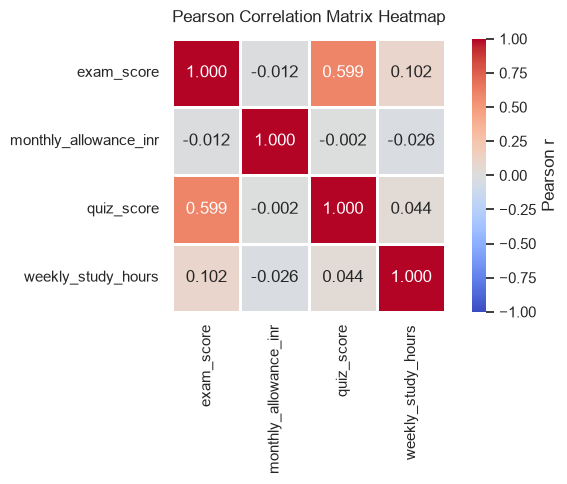

In [24]:
# --- Correlation Heatmap ---
# Filter out identifier columns (student_id) and categorical columns (preferred_language)
numeric_features = ["exam_score", "monthly_allowance_inr", "quiz_score", "weekly_study_hours"]
corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.8,
    cbar_kws={"label": "Pearson r"}
)

plt.title("Pearson Correlation Matrix Heatmap", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

In [25]:
# Comparative summary across the four numeric features
summary = pd.DataFrame({
    "mean": df[FEATURES].mean(),
    "median": df[FEATURES].median(),
    "std": df[FEATURES].std(),
    "IQR": df[FEATURES].quantile(0.75) - df[FEATURES].quantile(0.25),
    "skewness": df[FEATURES].skew(),
    "excess_kurtosis": df[FEATURES].kurtosis(),
})
display(summary)


,mean,median,std,IQR,skewness,excess_kurtosis
exam_score,71.931,72.150,7.658,10.890,0.132,0.211
monthly_allowance_inr,4414.375,4015.000,1909.942,2212.500,1.445,3.303
quiz_score,14.035,14.625,2.764,3.370,-1.124,1.407
weekly_study_hours,10.667,6.315,7.105,13.525,0.435,-1.532
